In [1]:
import sys
sys.path.append('../../../')

import matplotlib.pyplot as plt

# Import methods
import QGP.Defocusing.Methods as Def
import QGP.Focusing.Methods as Foc
from QGP.Soliton_Gen import *
from Utilities import *

import config

In [2]:
# Test energy is well calculated
def A(c, k):
    return 3*c**4*k**2 - 8*c**2*k**2 - 2*c**2*k + 8*k - 1

def B(c, k):
    return 3*c**2*k - 4*k - 1

def C(c, k):
    return c**2*k - 4*k - 1

def D(c, k):
    return np.sqrt((1 - 2*k) * (2 - c**2))

def L_c(c, k):
    return np.sqrt((2 - c**2) / (1 - 2*k))

# s = 1 for D_1 and s = -1 for D_3
def E_D_1_3(c, k, s):
    return (A(c, k) * np.arctan(np.sqrt(k) * L_c(c, k)) - s * np.sqrt(k) * B(c, k) * D(c, k)) / (16 * k**(3/2))

def E_tilde_D_1_3(c, k, s):
    return (A(c, k) * (np.arctan(np.sqrt(k) * L_c(c, k)) - np.pi / 2) - s * np.sqrt(k) * B(c, k) * D(c, k)) / (16 * k**(3/2))

def E_D_2(c, k):
    return -(A(c, k) * np.arctanh(np.sqrt(np.abs(k)) * L_c(c, k))- np.sqrt(np.abs(k)) * B(c, k) * D(c, k)) / (16 * np.abs(k)**(3/2))


# Cuspons in $D_3$

In [3]:
c = 2
k = 2

L = 60
N = 10_001

w_cuspon, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N)

Creating soliton...
Soliton created


In [4]:
c = 2
k = 2

L = 60
N = 10_000

w_cuspon_2, x_cuspon_2 = soliton(c, k, soliton_type="cuspon", L=L, N=N)

Creating soliton...
Soliton created


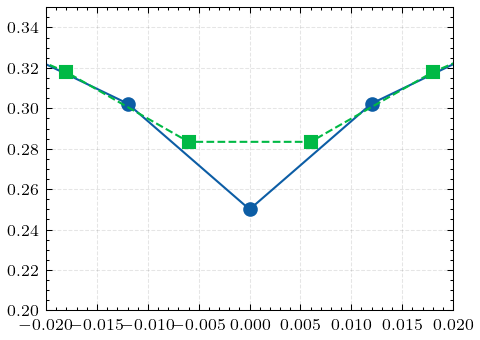

In [10]:
plt.plot(x_cuspon, norm(w_cuspon))
plt.plot(x_cuspon_2, norm(w_cuspon_2))

plt.xlim(-.02, .02)
plt.ylim(0.2, 0.35)
plt.show()

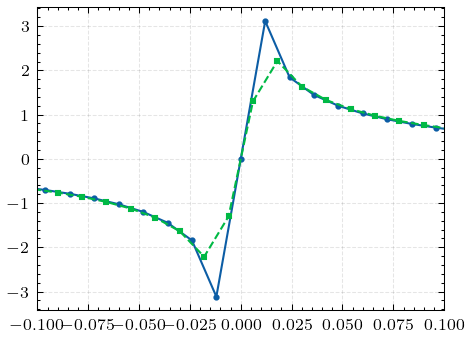

In [18]:
h = x_cuspon[1] - x_cuspon[0]

plt.plot(x_cuspon, np.real(np.gradient(w_cuspon, h)), ms=2)
plt.plot(x_cuspon_2, np.real(np.gradient(w_cuspon_2, h)), ms=2)

plt.xlim(-.1, .1)
#plt.ylim(0.2, 0.35)
plt.show()

In [19]:
h = x_cuspon[1] - x_cuspon[0]
w = w_cuspon

e_0 = h * np.sum(1/2 * norm(np.gradient(w, h)) + 1/4 * (1 - norm(w))**2 - k/4 * (np.gradient(norm(w), h))**2)
e_0

0.1641768325609844

In [20]:
h = x_cuspon_2[1] - x_cuspon_2[0]
w = w_cuspon_2

e_0 = h * np.sum(1/2 * norm(np.gradient(w, h)) + 1/4 * (1 - norm(w))**2 - k/4 * (np.gradient(norm(w), h))**2)
e_0

0.1521216538533196

In [21]:
E_tilde_D_1_3(c, k, -1)

0.15461085006242556

In [117]:
h = x_cuspon[1] - x_cuspon[0]
w = w_cuspon

e_0 = h * np.sum(1/2 * norm(np.gradient(w, h)) + 1/4 * (1 - norm(w))**2 - k/4 * (np.gradient(norm(w), h))**2)
e_0

0.15636288712844212

In [47]:
Nt = 5_000 #10_000
tf = 1e-3 #1 #15
pars = {"k":k}

w_cusp_num = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_cusp_num.set_init_array(w_cuspon)
w_cusp_num.solve(energy_perc=1, b_tol=1e-2)

Iteration  1  of  5000 . Newton Error:  1.5278386999136357e-12 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  1.5771538287301562e-12 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  1.6747624281133538e-12 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  1.8190590559501198e-12 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  2.008396846801512e-12 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  2.241485069478628e-12 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  2.5175243320049766e-12 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  2.836192293122244e-12 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  3.197537789870923e-12 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  3.6018732788164386e-12 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  4.049690799032113e-12 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  4.541598125772899e-12 . Tot

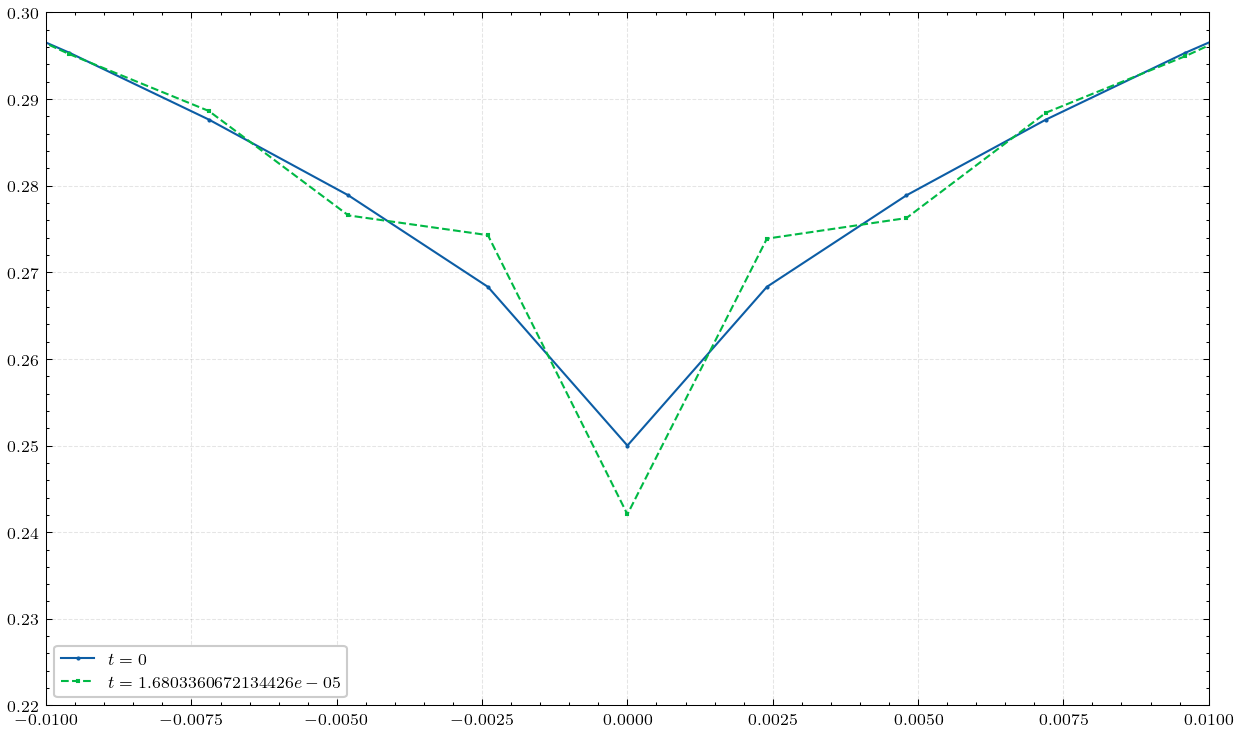

In [57]:
j = 84
plt.figure(figsize=(10, 6))
plt.plot(x_cuspon, norm(w_cusp_num.w[0]), ms=1, label=r"$t=0$")
plt.plot(x_cuspon, norm(w_cusp_num.w[j]), ms=1, label=r"$t={}$".format(j*w_cusp_num.dt))
#plt.xlim(-.1, .1)
#plt.ylim(0.2, 0.4)

#plt.xlim(-15, 15)

# Zero zoom
plt.xlim(-.01, .01)
plt.ylim(0.22, 0.3)

# Boundary zoom
#plt.xlim(57, 60.5)
#plt.ylim(0.9999999, 1.0000001)

plt.legend()
plt.show()

## Smooth with $\sqrt{x^2 + \varepsilon^2} - \varepsilon$

In [72]:
c = 2 #* np.sqrt(2)
k = 2
L = 60
N = 1_200_001

w_cuspon, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N)

Creating soliton...
Soliton created


In [73]:
dx = 2*L/(N-1)

In [74]:
eps_smooth = 1e-3

eps_smooth/np.log(1/eps_smooth), dx

(0.00014476482730108395, 0.0001)

In [75]:

eps_smooth = 1e-3

#w_cuspon, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N)
#w_cuspon_smooth_h, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N, eps_smooth=1e-6, reg_1=True)
w_cuspon_smooth_g, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N, eps_smooth=eps_smooth, reg_1=False, reg_2=True)

#w_cuspon_func, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N, as_func=True)

Creating soliton...
Soliton created


In [93]:
w_cuspon_smooth_h, x_cuspon = soliton(c, k, soliton_type="cuspon", L=L, N=N, eps_smooth=eps_smooth, reg_1=True)

Creating soliton...
Soliton created


In [77]:
h = x_cuspon[1] - x_cuspon[0]
w_smooth = w_cuspon
w_ns = w_cuspon_smooth_g

e_0_ns = h * np.sum(1/2 * norm(np.gradient(w_smooth, h)) + 1/4 * (1 - norm(w_smooth))**2 - k/4 * (np.gradient(norm(w_smooth), h))**2)
e_0 = h * np.sum(1/2 * norm(np.gradient(w_ns, h)) + 1/4 * (1 - norm(w_ns))**2 - k/4 * (np.gradient(norm(w_ns), h))**2)

print("Numerical energy: ", e_0_ns, "\nNumerical energy (smooth): ", e_0, "\nTheoretical: ", E_tilde_D_1_3(c, k, -1))
print("dx:", h, "epsilon:", 1e-2)

Numerical energy:  0.15468020215093828 
Numerical energy (smooth):  -0.13725850107977236 
Theoretical:  0.15461085006242556
dx: 0.00010000000000331966 epsilon: 0.01


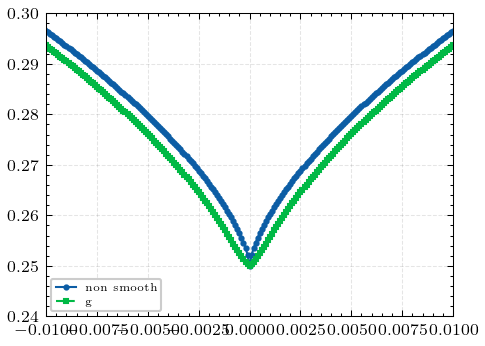

In [79]:
L_plot = 60
N_plot = 50_001
x_plot = np.linspace(-L_plot, L_plot, N_plot)

plt.plot(x_cuspon, norm(w_cuspon), ms=2, label="non smooth")
plt.plot(x_cuspon, norm(w_cuspon_smooth_g), ms=2, label="g")
#plt.plot(x_plot, norm(w_cuspon_func(x_plot)), marker="none", label="Interpolated cuspon")
#plt.plot(x_cuspon, norm(w_cuspon_smooth), marker="none", label="Smoothed cuspon")

plt.legend(fontsize=5)

#plt.xlim(-.5, .5)
#plt.ylim(0.24, 0.6)
#plt.xlim(-.1, .1)
plt.xlim(-.01, .01)
plt.ylim(0.24, .3)

plt.show()

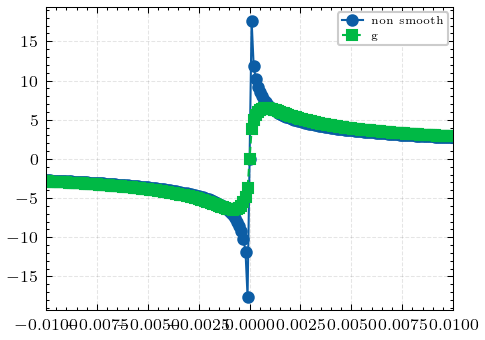

In [81]:
L_plot = 60
N_plot = 150_001
x_plot = np.linspace(-L_plot, L_plot, N_plot)

plt.plot(x_cuspon, np.real(np.gradient(w_cuspon, h)), ms=5, label="non smooth")
#plt.plot(x_cuspon, np.real(np.gradient(w_cuspon_smooth_h, h)), ms=5, label="h")
plt.plot(x_cuspon, np.real(np.gradient(w_cuspon_smooth_g, h)), ms=5, label="g")
#plt.plot(x_plot, norm(w_cuspon_func(x_plot)), marker="none", label="Interpolated cuspon")
#plt.plot(x_cuspon, norm(w_cuspon_smooth), marker="none", label="Smoothed cuspon")

plt.legend(fontsize=5)

#plt.xlim(-2, 2)
plt.xlim(-.01, .01)
#plt.ylim(0.24, .3)

plt.show()

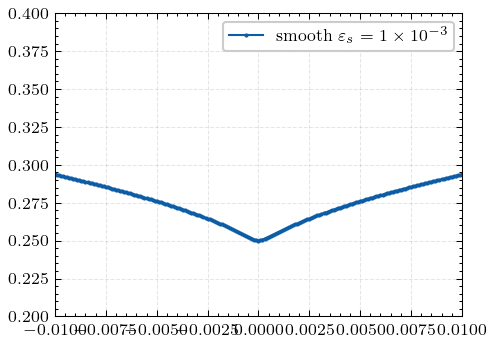

In [85]:
plt.plot(x_cuspon, norm(w_cuspon_smooth_g), ms=1, label=r"smooth $\varepsilon_s=${eps}".format(eps=sci_notation(eps_smooth)))
#plt.plot(x_cuspon, norm(w_cuspon), ms=1, label="non-smooth")

plt.legend()
plt.xlim(-.01, .01)
plt.ylim(.2, .4)
plt.show()

In [86]:
Nt = 5_000
tf = 1e-5
pars = {"k":k}

w_cusp_smooth_num = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_cusp_smooth_num.set_init_array(w_cuspon_smooth_g)
w_cusp_smooth_num.solve(energy_perc=1, b_tol=1e-2)

Iteration  1  of  5000 . Newton Error:  1.0913791977350071e-15 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  1.1822677220027488e-15 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  1.2501391512678647e-15 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  1.3199922169701136e-15 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  1.3625359202469563e-15 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  1.4252915771422128e-15 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  1.4747971445959042e-15 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  1.5097718391677828e-15 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  1.5407436822249494e-15 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  1.596314265593736e-15 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  6.89262594777658e-15 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  1.6436222617185887e-13 . 

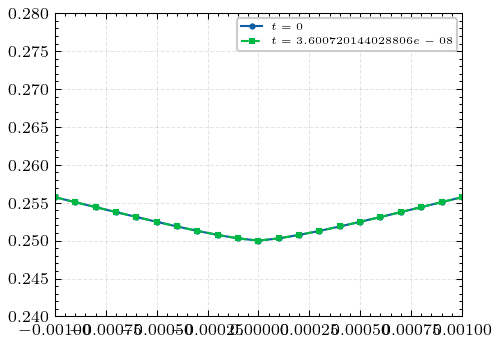

In [88]:
j = 18 #4999 #443
#plt.figure(figsize=(10, 6))
plt.plot(x_cuspon, norm(w_cusp_smooth_num.w[0]), ms=2, label=r"$t=0$")
plt.plot(x_cuspon, norm(w_cusp_smooth_num.w[j]), ms=2, label=r"$t={}$".format(j*w_cusp_smooth_num.dt))
#plt.xlim(-.01, .01)
#plt.ylim(0.225, 0.35)

plt.xlim(-.001, .001)
plt.ylim(0.24, 0.28)

#plt.xlim(-10, 10)
plt.legend(fontsize=5)
plt.show()

In [89]:
energy = w_cusp_smooth_num.get_energy()

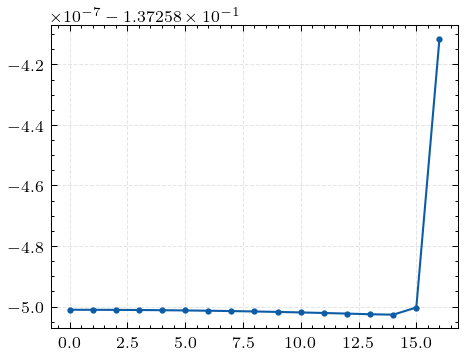

In [92]:
plt.plot(energy[:17], ms=2)

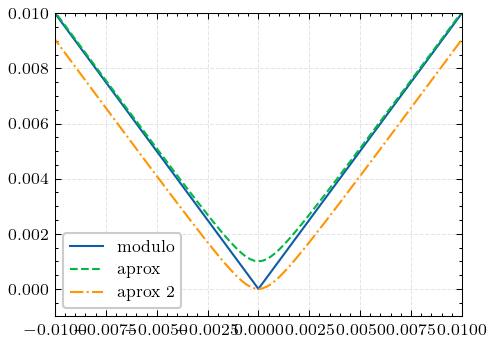

In [4]:
def modulo(x):
    """Devuelve |x|."""
    return np.abs(x)

def modulo_aprox(x, epsilon=1e-8):
    """Aproximación suave de |x|."""
    return np.sqrt(x**2 + epsilon**2)# - epsilon

def modulo_aprox_2(x, epsilon=1e-8):
    """Aproximación suave de |x|."""
    return np.sqrt(x**2 + epsilon**2) - epsilon

x = np.linspace(-1, 1, 10_001)

plt.plot(x, modulo(x), label="modulo", marker="none")
plt.plot(x, modulo_aprox(x, epsilon=1e-3), label="aprox", marker="none")
plt.plot(x, modulo_aprox_2(x, epsilon=1e-3), label="aprox 2", marker="none")
plt.legend()

plt.xlim(-.01, .01)
plt.ylim(-.001, 0.01)
plt.show()

# Tests

In [2]:
def sqrt_test(x):
    return np.minimum(np.sqrt(np.abs(x)), 1.0)

def tanh_test(x):
    return np.tanh(np.sqrt(np.abs(x)))

def exp_test(x):
    return np.sqrt(1 - np.exp(-np.abs(x)))

## $\sqrt{|x|}$

In [3]:
k = 2
L = 10
N = 20_001

Nt = 5_000 #10_000
tf = 1e-4 #1 #15
pars = {"k":k}

w_sqrt = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_sqrt.set_init_condition(sqrt_test)
w_sqrt.solve()

Iteration  1  of  5000 . Newton Error:  5.378213395674664e-11 . Total iteration:  1
Iteration  2  of  5000 . Newton Error:  5.4668578432382587e-11 . Total iteration:  1
Iteration  3  of  5000 . Newton Error:  5.663110091131132e-11 . Total iteration:  1
Iteration  4  of  5000 . Newton Error:  5.950998032027137e-11 . Total iteration:  1
Iteration  5  of  5000 . Newton Error:  6.310466150246458e-11 . Total iteration:  1
Iteration  6  of  5000 . Newton Error:  6.720832907663439e-11 . Total iteration:  1
Iteration  7  of  5000 . Newton Error:  7.162964259991533e-11 . Total iteration:  1
Iteration  8  of  5000 . Newton Error:  7.620209611980588e-11 . Total iteration:  1
Iteration  9  of  5000 . Newton Error:  8.078557784561966e-11 . Total iteration:  1
Iteration  10  of  5000 . Newton Error:  8.526437540409723e-11 . Total iteration:  1
Iteration  11  of  5000 . Newton Error:  8.954427055574059e-11 . Total iteration:  1
Iteration  12  of  5000 . Newton Error:  9.355005322135399e-11 . Total it

(-0.005, 0.015)

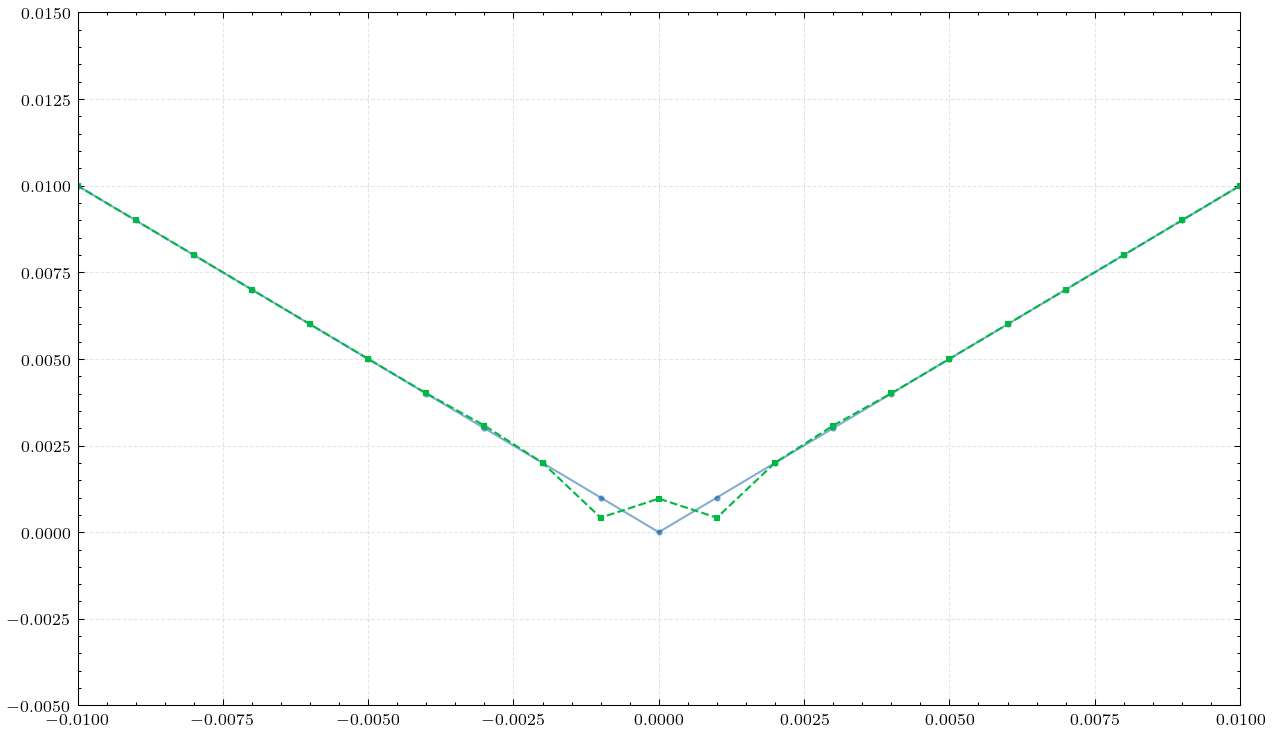

In [148]:
j = 30
plt.figure(figsize=(10, 6))
plt.plot(w_sqrt.x, norm(w_sqrt.w[0]), label="init", alpha=0.5, ms=2)
plt.plot(w_sqrt.x, norm(w_sqrt.w[j]), label=r"$t={}$".format(j*w_sqrt.dt), ms=2)
plt.xlim(-.01, .01)
plt.ylim(-0.005, 0.015)

## $\tanh(\sqrt{|x|})$

In [4]:
k = 2
L = 50
N = 20_001

Nt = 5_000 #10_000
tf = 1e-2 #1 #15
pars = {"k":k}

w_tanh = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_tanh.set_init_condition(tanh_test)
w_tanh.solve()

Iteration  1  of  5000 . Newton Error:  7.336120124532903e-16 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  5.26442144107714e-16 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  1.0954715250260677e-15 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  2.1787243197248966e-15 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  2.998262452628101e-15 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  3.1849758376074266e-15 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  2.6975294495795103e-15 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  1.811364303694415e-15 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  9.632073490874964e-16 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  5.199211274981608e-16 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  4.802275260523287e-16 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  5.224591808996672e-16 . Total 

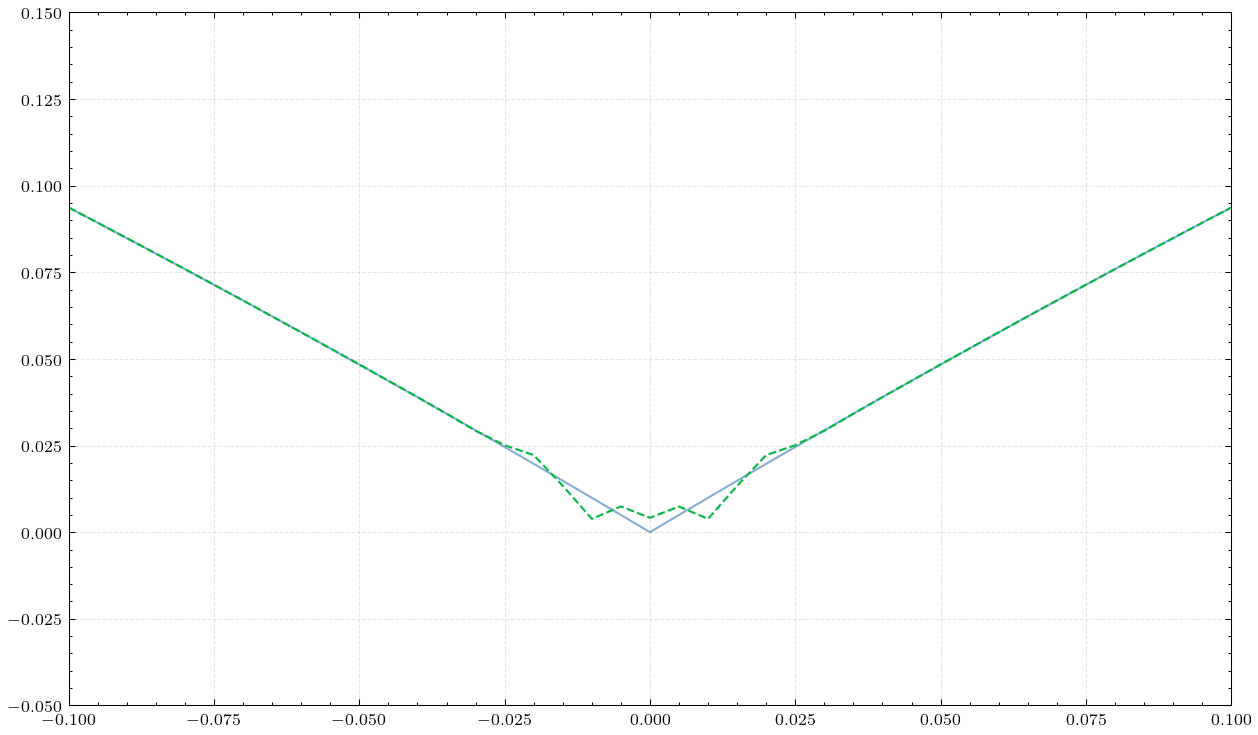

In [181]:
j = 20
plt.figure(figsize=(10, 6))
plt.plot(w_tanh.x, norm(w_tanh.w[0]), label="init", alpha=0.5, marker="none")#, ms=2)
plt.plot(w_tanh.x, norm(w_tanh.w[j]), label=r"$t={}$".format(j*w_sqrt.dt), marker="none")#, ms=2)
plt.xlim(-.1, .1)
plt.ylim(-0.05, 0.15)
plt.show()

## $1 - e^{-|x|}$

In [5]:
k = 2
L = 50
N = 20_001

Nt = 5_000 #10_000
tf = 1e-2 #1 #15
pars = {"k":k}

w_exp = Def.CNFD(L, N, Nt, tf, pars, "neumann", order=2)
w_exp.set_init_condition(exp_test)
w_exp.solve()

Iteration  1  of  5000 . Newton Error:  6.946983754722064e-16 . Total iteration:  2
Iteration  2  of  5000 . Newton Error:  4.463695123443886e-16 . Total iteration:  2
Iteration  3  of  5000 . Newton Error:  1.0565104122840002e-15 . Total iteration:  2
Iteration  4  of  5000 . Newton Error:  2.163503763429682e-15 . Total iteration:  2
Iteration  5  of  5000 . Newton Error:  2.992826417461159e-15 . Total iteration:  2
Iteration  6  of  5000 . Newton Error:  3.1807487815170025e-15 . Total iteration:  2
Iteration  7  of  5000 . Newton Error:  2.6891580533313963e-15 . Total iteration:  2
Iteration  8  of  5000 . Newton Error:  1.795662554124705e-15 . Total iteration:  2
Iteration  9  of  5000 . Newton Error:  9.230048269296316e-16 . Total iteration:  2
Iteration  10  of  5000 . Newton Error:  4.468578761886349e-16 . Total iteration:  2
Iteration  11  of  5000 . Newton Error:  3.9404294976614406e-16 . Total iteration:  2
Iteration  12  of  5000 . Newton Error:  4.480000760480734e-16 . Total

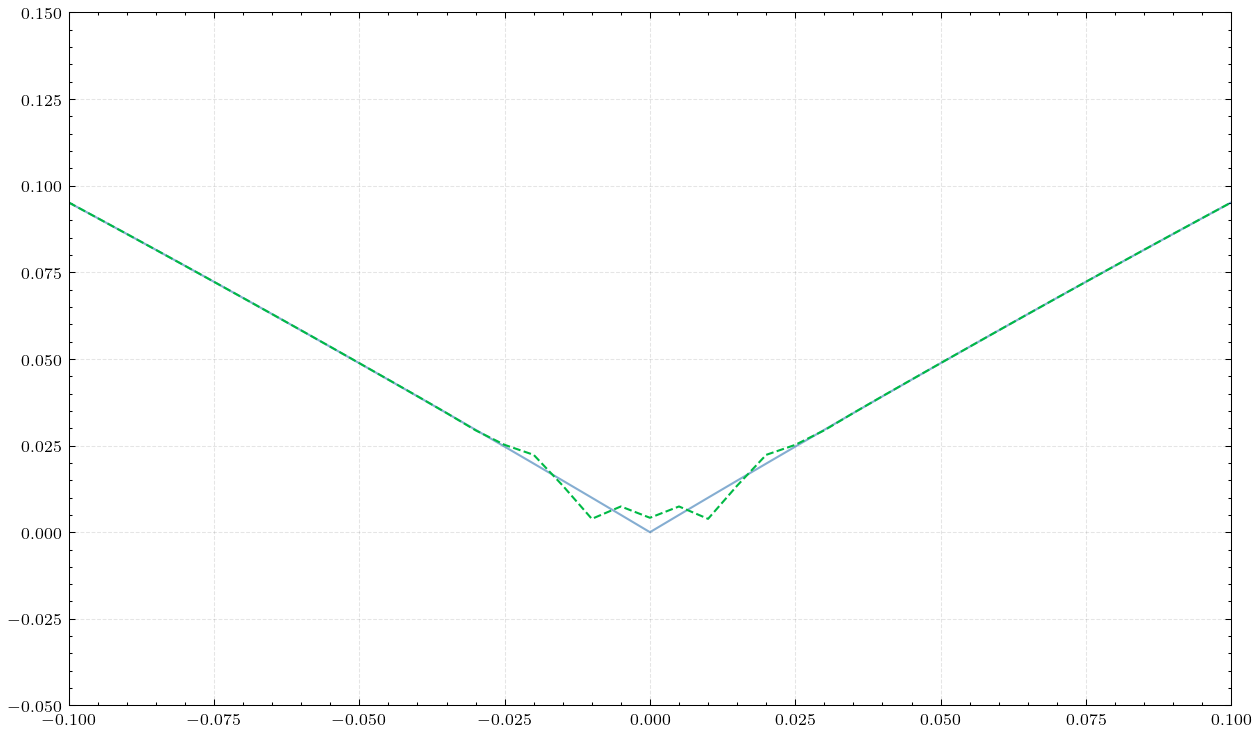

In [180]:
j = 20
plt.figure(figsize=(10, 6))
plt.plot(w_exp.x, norm(w_exp.w[0]), label="init", alpha=0.5, marker="none")#, ms=2)
plt.plot(w_exp.x, norm(w_exp.w[j]), label=r"$t={}$".format(j*w_sqrt.dt), marker="none")#, ms=2)
plt.xlim(-.1, .1)
plt.ylim(-0.05, 0.15)

plt.show()

Intentar con identidad (-1 a 1) y tangente hiperbólica

# Cuspons in $\mathcal{B}_+$

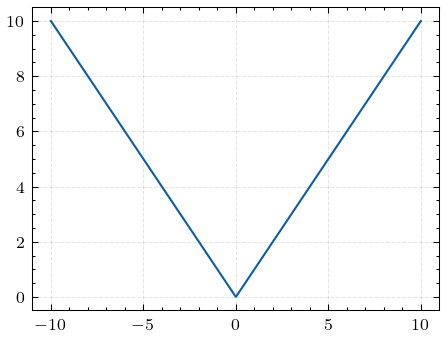

In [77]:
x = np.linspace(-10, 10, 1000)
eps = 1e-5
plt.plot(x, np.sqrt(x**2 + eps**2), marker="none")